### Joint Loss and Hyperparameter Optimization for Wind Offshore Forecasting

This notebook tunes LightGBM, XGBoost, and CatBoost for the production-like history regime selected in notebook 4 (**365 days loockup** and refit **every day**).

The training loss and the model hyperparameters are tuned together. Each loss receives its own Optuna study and the same initial number of trials within a model family. This is important because parameters that work well with squared error are not necessarily best for absolute or Huber loss.

The reason I decided to test different loss functions in the first place is that, according to the data in Notebook 2, the MAE rises significantly at high capacity factors. In my view, this is potentially more critical than elevated errors in the lower range, when all wind farms are producing large amounts of energy, it sends a stronger price signal than when they are generating moderate output.

Therefore, at this stage, I would prefer a model that performs better in the mid-to-high range than in the low range.

The workflow follows four rules:

1. The history window and refit interval are explicit settings. A `365/1` regime uses the latest 365 calendar days and refits every day. Changing the settings to `270/7`, for example, trains on 270 days and keeps each fitted model for seven target days.
2. The main selection metric is mean daily MAE on clipped capacity-factor predictions. Training loss, sample weights, and tree parameters are search variables; the selection metric stays fixed.
3. The validation targets never control gradients or early stopping. The number of boosting rounds is tuned directly, so **every row** in the selected history window is used for training.
4. The final holdout length comes from `HOLDOUT_DAYS` in `.env`, following the same convention as the earlier refactored notebooks.

`Run All` performs data and implementation checks. The long stages are controlled by `RUN_SEARCH`, `RUN_FINALISTS`, and `RUN_HOLDOUT`. Their outputs are cached and can be resumed.


### Why the Loss and Hyperparameters Are Tuned Together

I decided to tune the hyperparameters and the loss function jointly, as I wanted to achieve maximum consistency between them.

This notebook therefore treats each loss as a separate conditional search space:

- LightGBM: L2, L1, and Huber;
- XGBoost: squared error, absolute error, and Pseudo-Huber;
- CatBoost: RMSE, MAE, and Huber.

Each branch includes an unweighted baseline. It can also test capacity-factor weights of the form

`weight = 1 + alpha * capacity_factor ** power`.

These weights use training targets only. They are a hypothesis, not an automatic correction. The error increase at high observed capacity factors can also come from rare observations, grid constraints, or regression toward the mean.

The train-versus-validation gap is reported only as a diagnostic and it is not used as a selection.

### Configuration Parameters

`TRAIN_WINDOW_DAYS` and `RETRAIN_INTERVAL_DAYS` — These variables define the training history regime. A setup of `365/1` represents the current production plan, while both values can be modified to test alternative historical windows.

`RUN_SMOKE_CHECKS` — When set to True, a full dry run is executed to print the execution schedule and runtime estimates before starting heavy computations.

`RUN_SEARCH` — Setting this parameter to True initiates the main hyperparameter optimization process. If the best-so-far loss curves continue to improve or parameters frequently hit boundary limits, `TRIALS_PER_LOSS` is typically increased.

`RUN_FINALISTS` — This flag is activated after each study reaches its allocated trial budget. It routes the shortlisted candidates through the full development schedule to freeze the top-performing configuration for each model family.

`RUN_HOLDOUT` — This step is enabled only after the finalist selection file is generated. It generates the final results table and interactive charts without modifying any hyperparameter choices based on holdout performance.

In [1]:
# Core imports and project paths
import hashlib
import importlib.metadata
import json
import os
import platform
import time
import uuid
from pathlib import Path

import catboost as cb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import plotly.graph_objects as go
import pyrootutils
import xgboost as xgb
from dotenv import load_dotenv
from IPython.display import display
from tqdm.auto import tqdm


load_dotenv()


# Find the project root and make local modules importable.
PROJECT_ROOT = pyrootutils.setup_root(
    search_from=__file__ if "__file__" in locals() else ".",
    indicator=".gitignore",
    pythonpath=True,
)


# Use the same thread-detection helper as the earlier notebooks.
from utils.utils_for_notebooks import get_available_threads


DATASET_PATH = (
    PROJECT_ROOT
    / "data/datasets/offshore_dataset_15m_interpolated_14_points_proxy_2024-03-14_to_2026-06-11.parquet"
)
NOTEBOOK_PATH = (
    PROJECT_ROOT
    / "notebooks/research_wind_offshore_model/5_joint_loss_hpo_wind_off.ipynb"
)
RESULTS_ROOT = PROJECT_ROOT / "results" / "offshore_joint_loss_hpo"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)


# Production regime. Change these two values together when testing another regime.
TRAIN_WINDOW_DAYS = 365
RETRAIN_INTERVAL_DAYS = 1


# Experiment settings.
HOLDOUT_DAYS = int(os.getenv("HOLDOUT_DAYS") or 28)
DAY_AHEAD_DEADLINE_HOUR = 12
N_SEARCH_REFIT_BLOCKS = 96
TOP_K_PER_LOSS = 2
FINALISTS_PER_MODEL = 2
SEED = 1337
FINAL_SEEDS = [1337, 2027]
N_THREADS = get_available_threads()


# GPU is allowed only for a backend validated on this workload.
# The measured CPU/GPU comparison did not justify a production switch.
ALLOW_GPU = False
VALIDATED_GPU_BRANCHES = frozenset()


# Starting budgets. Increasing a budget continues the existing study.
TRIALS_PER_LOSS = {
    "LightGBM": 50,
    "XGBoost": 50,
    "CatBoost": 50,
}


LOSSES = {
    "LightGBM": ["l2", "l1", "huber"],
    "XGBoost": ["l2", "l1", "huber"],
    "CatBoost": ["l2", "l1", "huber"],
}


# Long stages are disabled by default.
RUN_SMOKE_CHECKS = True
RUN_SEARCH = False
RUN_FINALISTS = True
RUN_HOLDOUT = True


if TRAIN_WINDOW_DAYS < 1:
    raise ValueError("TRAIN_WINDOW_DAYS must be positive.")
if RETRAIN_INTERVAL_DAYS < 1:
    raise ValueError("RETRAIN_INTERVAL_DAYS must be positive.")
if HOLDOUT_DAYS < 1:
    raise ValueError("HOLDOUT_DAYS must be positive.")


VERSIONS = {
    package: importlib.metadata.version(package)
    for package in [
        "numpy",
        "pandas",
        "pyarrow",
        "lightgbm",
        "xgboost",
        "catboost",
        "optuna",
        "plotly",
    ]
}
VERSIONS.update(
    python=platform.python_version(),
    platform=platform.platform(),
)


optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:.5f}")


print("Library versions:", VERSIONS)
print(f"Model threads available to this process: {N_THREADS}")
print(f"Selected history regime: {TRAIN_WINDOW_DAYS}/{RETRAIN_INTERVAL_DAYS}")
print(f"Holdout days from .env: {HOLDOUT_DAYS}")

if N_SEARCH_REFIT_BLOCKS < 1 or TOP_K_PER_LOSS < 1 or FINALISTS_PER_MODEL < 1:
    raise ValueError("Search and finalist counts must be positive.")
if not FINAL_SEEDS or FINAL_SEEDS[0] != SEED or len(set(FINAL_SEEDS)) != len(FINAL_SEEDS):
    raise ValueError("FINAL_SEEDS must start with SEED and contain unique seeds.")
if VALIDATED_GPU_BRANCHES:
    raise ValueError("No GPU branch is approved by the current benchmark; revalidate before changing the backend.")
print(f"ALLOW_GPU={ALLOW_GPU}; effective backend: CPU (see the measured comparison below).")


Library versions: {'numpy': '2.4.4', 'pandas': '3.0.2', 'pyarrow': '23.0.1', 'lightgbm': '4.6.0', 'xgboost': '3.3.0', 'catboost': '1.2.10', 'optuna': '4.9.0', 'plotly': '6.8.0', 'python': '3.13.12', 'platform': 'Windows-11-10.0.26200-SP0'}
Model threads available to this process: 16
Selected history regime: 365/1
Holdout days from .env: 28
ALLOW_GPU=False; effective backend: CPU (see the measured comparison below).


d:\python_projects\entsoe_1st_try\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Loading the Selected Dataset

The notebook uses the same interpolated 14-point feature set as notebook 4. Absolute timestamps, installed capacity, actual generation, and the target **are excluded from the predictors** as before to prevent direct data leakage.

The checks below require a complete 15-minute target grid, including the 92- and 100-row days created by daylight-saving time. They also verify that every weather forecast was issued before its target time.

In [2]:
TARGET_COL = "capacity_factor"
TARGET_TIME_COL = "dt_berlin"
ISSUE_TIME_COL = "dt_run_utc"
TIMEZONE = "Europe/Berlin"


NON_FEATURE_COLS = {
    TARGET_COL,
    TARGET_TIME_COL,
    ISSUE_TIME_COL,
    "capacity",
    "gen_wind_off_act",
}


df = pd.read_parquet(DATASET_PATH).reset_index(drop=True)
df[TARGET_TIME_COL] = (
    pd.to_datetime(df[TARGET_TIME_COL], utc=True)
    .dt.tz_convert(TIMEZONE)
)
df[ISSUE_TIME_COL] = pd.to_datetime(df[ISSUE_TIME_COL], utc=True)
df = df.sort_values(TARGET_TIME_COL).reset_index(drop=True)


FEATURE_COLS = [
    column
    for column in df.columns
    if column not in NON_FEATURE_COLS
    and pd.api.types.is_numeric_dtype(df[column])
]


if not FEATURE_COLS:
    raise ValueError("No numeric feature columns were found.")
if df[TARGET_TIME_COL].duplicated().any():
    raise ValueError("Target timestamps must be unique.")
if df[[TARGET_TIME_COL, ISSUE_TIME_COL]].isna().any().any():
    raise ValueError("Target and issue timestamps must be complete.")
if not np.isfinite(df[FEATURE_COLS + [TARGET_COL]].to_numpy()).all():
    raise ValueError("Features and target must be finite.")
if not df[TARGET_COL].between(0, 1).all():
    raise ValueError("Capacity factor must remain between zero and one.")


X = df[FEATURE_COLS].astype("float32")
y = df[TARGET_COL].to_numpy(dtype="float64", copy=True)


target_time_utc = df[TARGET_TIME_COL].dt.tz_convert("UTC")
local_days = df[TARGET_TIME_COL].dt.tz_localize(None).dt.normalize()
calendar = pd.date_range(local_days.min(), local_days.max(), freq="D")


DAY_ROWS = {
    day: np.flatnonzero(local_days.eq(day))
    for day in calendar
}


def production_times(target_day):
    """Return the training cutoff and forecast deadline for one target day."""
    target_day = pd.Timestamp(target_day)

    if target_day.tzinfo is not None or target_day != target_day.normalize():
        raise ValueError("target_day must be a naive local calendar day.")

    cutoff_local = (target_day - pd.DateOffset(days=1)).tz_localize(TIMEZONE)
    deadline_local = (
        target_day
        - pd.DateOffset(days=1)
        + pd.Timedelta(hours=DAY_AHEAD_DEADLINE_HOUR)
    ).tz_localize(TIMEZONE)

    return cutoff_local.tz_convert("UTC"), deadline_local.tz_convert("UTC")


def history_bounds(training_cutoff):
    """Return the selected calendar-day history interval in UTC."""
    cutoff_local = training_cutoff.tz_convert(TIMEZONE)
    history_start_local = cutoff_local - pd.DateOffset(days=TRAIN_WINDOW_DAYS)

    return history_start_local.tz_convert("UTC"), training_cutoff


def expected_target_grid(target_day):
    """Build the expected 15-minute UTC grid for one local target day."""
    start = target_day.tz_localize(TIMEZONE)
    end = (target_day + pd.DateOffset(days=1)).tz_localize(TIMEZONE)

    return pd.date_range(
        start,
        end,
        freq="15min",
        inclusive="left",
    ).tz_convert("UTC")


for day, row_index in DAY_ROWS.items():
    observed = target_time_utc.iloc[row_index].array.asi8
    expected = expected_target_grid(day).asi8

    if not np.array_equal(observed, expected):
        raise ValueError(f"Incomplete 15-minute target grid for {day.date()}.")


if not (df[ISSUE_TIME_COL] < target_time_utc).all():
    raise ValueError("Every weather forecast must be issued before its target time.")


print(f"Rows: {len(df):,}")
print(f"Features: {len(FEATURE_COLS)}")
print(f"Target dates: {calendar.min().date()} to {calendar.max().date()}")

Rows: 78,620
Features: 40
Target dates: 2024-03-15 to 2026-06-11


### Production-Like Refit Schedule

A refit block starts on target day D. The model trains once using the selected history ending **at D−1 00:00**, after the last interval of **D−2**. The prediction must be ready by **12:00 on D−1**.

With `RETRAIN_INTERVAL_DAYS = 1`, the block contains one target day. With a value of 7 for example, **the same fitted model** is used for seven target days. New weather inputs may still arrive **every day**, only the **model parameters** stay fixed between refits.

The last `HOLDOUT_DAYS` are kept outside hyperparameter search and finalist selection. The development period begins at the first date with a complete training window. Search acceleration selects complete refit blocks spread evenly through development. It never replaces the chosen refit policy with a cheaper one.

The refit cadence continues across the holdout boundary. For a weekly regime, the first holdout days may use the model fitted during development. **The boundary does not force an extra refit**.


In [3]:
holdout_start = (
    calendar.max()
    + pd.DateOffset(days=1 - HOLDOUT_DAYS)
)


eligible_starts = []

for target_day in calendar[calendar < holdout_start]:
    training_cutoff, _ = production_times(target_day)
    history_start, _ = history_bounds(training_cutoff)

    if history_start >= target_time_utc.min():
        eligible_starts.append(target_day)


if not eligible_starts:
    raise ValueError("The dataset is too short for the selected training window.")


development_start = eligible_starts[0]
development_days = calendar[
    (calendar >= development_start)
    & (calendar < holdout_start)
]
holdout_days = calendar[calendar >= holdout_start]


def build_refit_blocks(target_days):
    """Build consecutive refit blocks for one evaluation period."""
    target_days = pd.DatetimeIndex(target_days)

    if target_days.empty:
        raise ValueError("The evaluation period must contain at least one day.")

    blocks = []
    period_end = target_days.max() + pd.DateOffset(days=1)
    # Anchor every phase to the first development day. A holdout boundary
    # must not trigger an extra refit in a weekly production schedule.
    offset = (target_days.min() - development_start).days
    block_start = development_start + pd.DateOffset(
        days=(offset // RETRAIN_INTERVAL_DAYS) * RETRAIN_INTERVAL_DAYS
    )

    while block_start < period_end:
        block_end = min(
            block_start + pd.DateOffset(days=RETRAIN_INTERVAL_DAYS),
            period_end,
        )

        block_days = target_days[
            (target_days >= block_start)
            & (target_days < block_end)
        ]

        training_cutoff, refit_deadline = production_times(block_start)
        history_start, history_end = history_bounds(training_cutoff)

        train_index = np.flatnonzero(
            target_time_utc.ge(history_start)
            & target_time_utc.lt(history_end)
        )
        valid_index = np.concatenate(
            [DAY_ROWS[day] for day in block_days]
        )

        if local_days.iloc[train_index].nunique() != TRAIN_WINDOW_DAYS:
            raise ValueError(f"Incomplete training history for {block_start.date()}.")
        if np.intersect1d(train_index, valid_index).size:
            raise ValueError("Training and validation rows overlap.")
        if target_time_utc.iloc[train_index].max() >= training_cutoff:
            raise ValueError("Training data crosses the production cutoff.")
        if refit_deadline >= target_time_utc.iloc[valid_index].min():
            raise ValueError("The first target interval is before the refit deadline.")

        # Each target day's weather input must exist by its own day-ahead deadline.
        for target_day in block_days:
            _, target_deadline = production_times(target_day)
            target_rows = DAY_ROWS[target_day]

            if not (df[ISSUE_TIME_COL].iloc[target_rows] < target_deadline).all():
                raise ValueError(f"Weather data arrives too late for {target_day.date()}.")

        blocks.append(
            {
                "block": len(blocks) + 1,
                "start": block_start,
                "end": block_end,
                "target_days": block_days,
                "train": train_index,
                "valid": valid_index,
                "history_start": history_start,
                "training_cutoff": training_cutoff,
                "refit_deadline": refit_deadline,
            }
        )

        block_start = block_end

    covered_days = pd.DatetimeIndex(
        np.concatenate([block["target_days"] for block in blocks])
    )

    if not covered_days.equals(target_days):
        raise ValueError("Refit blocks do not cover the evaluation period exactly once.")

    return blocks


development_blocks = build_refit_blocks(development_days)
holdout_blocks = build_refit_blocks(holdout_days)


n_search_blocks = min(N_SEARCH_REFIT_BLOCKS, len(development_blocks))
search_block_positions = [
    section[len(section) // 2]
    for section in np.array_split(np.arange(len(development_blocks)), n_search_blocks)
]
search_blocks = [development_blocks[position] for position in search_block_positions]


schedule_audit = pd.DataFrame(
    [
        {
            "phase": phase,
            "block": block["block"],
            "start": block["start"],
            "end": block["end"],
            "target_days": len(block["target_days"]),
            "train_rows": len(block["train"]),
            "predict_rows": len(block["valid"]),
            "history_start": block["history_start"],
            "training_cutoff": block["training_cutoff"],
            "refit_deadline": block["refit_deadline"],
        }
        for phase, blocks in [
            ("development", development_blocks),
            ("holdout", holdout_blocks),
        ]
        for block in blocks
    ]
)


print(
    f"Development: {development_days.min().date()} to "
    f"{development_days.max().date()} | "
    f"{len(development_days)} days | {len(development_blocks)} refits"
)
print(
    f"Holdout: {holdout_days.min().date()} to "
    f"{holdout_days.max().date()} | "
    f"{len(holdout_days)} days | {len(holdout_blocks)} refits"
)
print(f"Sparse search refits per trial: {len(search_blocks)}")


display(schedule_audit.iloc[[0, len(development_blocks) - 1, -1]])
display(
    pd.DataFrame(
        {
            "search_block": range(1, len(search_blocks) + 1),
            "start": [block["start"] for block in search_blocks],
            "target_days": [len(block["target_days"]) for block in search_blocks],
        }
    )
)


Development: 2025-03-16 to 2026-05-14 | 425 days | 425 refits
Holdout: 2026-05-15 to 2026-06-11 | 28 days | 28 refits
Sparse search refits per trial: 96


,phase,block,start,end,target_days,train_rows,predict_rows,history_start,training_cutoff,refit_deadline
0,development,1,2025-03-16,2025-03-17,1,35040,96,2024-03-14 23:00:00+00:00,2025-03-14 23:00:00+00:00,2025-03-15 11:00:00+00:00
424,development,425,2026-05-14,2026-05-15,1,35040,96,2025-05-12 22:00:00+00:00,2026-05-12 22:00:00+00:00,2026-05-13 10:00:00+00:00
452,holdout,28,2026-06-11,2026-06-12,1,35040,96,2025-06-09 22:00:00+00:00,2026-06-09 22:00:00+00:00,2026-06-10 10:00:00+00:00


,search_block,start,target_days
0,1,2025-03-18,1
1,2,2025-03-23,1
2,3,2025-03-28,1
3,4,2025-04-02,1
4,5,2025-04-07,1
...,...,...,...
91,92,2026-04-27,1
92,93,2026-05-01,1
93,94,2026-05-05,1
94,95,2026-05-09,1


### Search Spaces

The ranges below are broad enough to cover shallow, strongly regularized models and larger ensembles without making the first search unnecessarily expensive.

| Model | Tuned parameters |
|---|---|
| LightGBM | 100–1600 rounds, learning rate 0.015–0.12, depth 3–8, leaves constrained by depth, minimum leaf size 24–1536, row and feature sampling, L1 and L2 regularization |
| XGBoost | 100–1600 rounds, learning rate 0.015–0.12, depth 2–7, minimum child weight 1–256, row and feature sampling, gamma, L1 and L2 regularization |
| CatBoost | 100–1600 rounds, learning rate 0.015–0.12, symmetric-tree depth 3–8, L2 regularization, random strength 0–4, Bernoulli row sampling, and feature sampling |
| Weighting & Loss | Huber transition parameters 0.02–0.20 (in capacity-factor units), capacity-factor weight power 0.5–4.0 |


Huber transition parameters are measured in capacity-factor units and tuned from 0.02 to 0.20. The library implementations are related but not identical: XGBoost uses Pseudo-Huber.

The number of rounds is tuned directly. Early stopping is deliberately absent because using an outer validation block for both stopping and scoring would make the score optimistic.

A separate inner stopping window could be added later, but it would define a different training policy and must receive a new cache identity.

Three coordinates are structured to make TPE more efficient. `leaf_fraction`
has fixed bounds and is converted to a valid LightGBM leaf count for the sampled
depth. Exact zero L1 regularization and XGBoost split gamma are separate switches;
positive values use continuous logarithmic ranges. `boosting_budget` represents
`learning_rate * rounds`; the resolved number of trees is kept between 100 and
1600. This avoids many implausible corners without using future targets for early
stopping.

Inactive regularization and weight parameters are omitted from each trial. Each loss starts with 50 trials on 96 blocks - this is quite a large search budget, but still not a convergence guarantee.

CatBoost Huber uses explicit Gradient leaf estimation. The earlier implicit
Newton update produced extreme raw forecasts on some dates and seeds. Raw
prediction diagnostics **remain visible** before clipping.


In [4]:
def baseline_config(model_name, loss_name="l2"):
    """Return the moderately regularized baseline from notebook 4."""
    if model_name == "LightGBM":
        model_params = {
            "n_estimators": 200,
            "learning_rate": 0.05,
            "max_depth": 4,
            "num_leaves": 15,
            "min_child_samples": 50,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
            "reg_alpha": 0.1,
            "reg_lambda": 5.0,
        }

    elif model_name == "XGBoost":
        model_params = {
            "n_estimators": 200,
            "learning_rate": 0.05,
            "max_depth": 4,
            "min_child_weight": 50.0,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
            "gamma": 0.0,
            "reg_alpha": 0.1,
            "reg_lambda": 5.0,
        }

    elif model_name == "CatBoost":
        model_params = {
            "iterations": 200,
            "learning_rate": 0.05,
            "depth": 4,
            "l2_leaf_reg": 5.0,
            "random_strength": 1.0,
            "subsample": 0.8,
            "rsm": 0.8,
        }

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return {
        "model": model_name,
        "loss": loss_name,
        "model_params": model_params,
        "huber_delta": 0.1 if loss_name == "huber" else None,
        "weighting": "uniform",
        "weight_alpha": 0.0,
        "weight_power": 1.0,
    }


def suggest_config(trial, model_name, loss_name):
    """Sample one valid conditional configuration for a model and loss."""
    learning_rate = trial.suggest_float(
        "learning_rate",
        0.015,
        0.12,
        log=True,
    )

    # Most useful boosting configurations follow a diagonal relation between
    # the learning rate and the number of trees. Sampling their product avoids
    # spending many trials on clearly excessive or insufficient combinations.
    boosting_budget = trial.suggest_float(
        "boosting_budget",
        5.0,
        45.0,
        log=True,
    )
    rounds = int(
        np.clip(
            round(boosting_budget / learning_rate),
            100,
            1600,
        )
    )

    if model_name == "LightGBM":
        max_depth = trial.suggest_int("max_depth", 3, 8)

        # leaf_fraction has fixed bounds and the same relative meaning for
        # every depth. The resolved leaf count respects LightGBM's depth limit.
        leaf_fraction = trial.suggest_float("leaf_fraction", 0.0, 1.0)
        maximum_leaves = min(127, 2**max_depth)
        num_leaves = int(
            round(7 + leaf_fraction * (maximum_leaves - 7))
        )

        use_reg_alpha = trial.suggest_categorical(
            "use_reg_alpha",
            [False, True],
        )
        reg_alpha = (
            trial.suggest_float(
                "reg_alpha",
                1e-4,
                10.0,
                log=True,
            )
            if use_reg_alpha
            else 0.0
        )

        model_params = {
            "n_estimators": rounds,
            "learning_rate": learning_rate,
            "max_depth": max_depth,
            "num_leaves": num_leaves,
            "min_child_samples": trial.suggest_int(
                "min_child_samples",
                24,
                1536,
                log=True,
            ),
            "subsample": trial.suggest_float("subsample", 0.65, 1.0),
            "colsample_bytree": trial.suggest_float(
                "colsample_bytree",
                0.6,
                1.0,
            ),
            "reg_alpha": reg_alpha,
            "reg_lambda": trial.suggest_float(
                "reg_lambda",
                0.01,
                50.0,
                log=True,
            ),
        }

    elif model_name == "XGBoost":
        use_gamma = trial.suggest_categorical(
            "use_gamma",
            [False, True],
        )
        gamma = (
            trial.suggest_float(
                "gamma",
                1e-4,
                0.1,
                log=True,
            )
            if use_gamma
            else 0.0
        )

        use_reg_alpha = trial.suggest_categorical(
            "use_reg_alpha",
            [False, True],
        )
        reg_alpha = (
            trial.suggest_float(
                "reg_alpha",
                1e-4,
                10.0,
                log=True,
            )
            if use_reg_alpha
            else 0.0
        )

        model_params = {
            "n_estimators": rounds,
            "learning_rate": learning_rate,
            "max_depth": trial.suggest_int("max_depth", 2, 7),
            "min_child_weight": trial.suggest_float(
                "min_child_weight",
                1.0,
                256.0,
                log=True,
            ),
            "subsample": trial.suggest_float("subsample", 0.65, 1.0),
            "colsample_bytree": trial.suggest_float(
                "colsample_bytree",
                0.6,
                1.0,
            ),
            "gamma": gamma,
            "reg_alpha": reg_alpha,
            "reg_lambda": trial.suggest_float(
                "reg_lambda",
                0.01,
                50.0,
                log=True,
            ),
        }

    elif model_name == "CatBoost":
        model_params = {
            "iterations": rounds,
            "learning_rate": learning_rate,
            "depth": trial.suggest_int("depth", 3, 8),
            "l2_leaf_reg": trial.suggest_float(
                "l2_leaf_reg",
                1.0,
                50.0,
                log=True,
            ),
            "random_strength": trial.suggest_float(
                "random_strength",
                0.0,
                4.0,
            ),
            "subsample": trial.suggest_float("subsample", 0.65, 1.0),
            "rsm": trial.suggest_float("rsm", 0.6, 1.0),
        }

    else:
        raise ValueError(f"Unknown model: {model_name}")

    weighting = trial.suggest_categorical(
        "weighting",
        ["uniform", "capacity_factor"],
    )

    if weighting == "capacity_factor":
        weight_alpha = trial.suggest_float("weight_alpha", 0.1, 4.0)
        weight_power = trial.suggest_float("weight_power", 0.5, 4.0)
    else:
        weight_alpha = 0.0
        weight_power = 1.0

    huber_delta = None
    if loss_name == "huber":
        huber_delta = trial.suggest_float(
            "huber_delta",
            0.02,
            0.20,
            log=True,
        )

    return {
        "model": model_name,
        "loss": loss_name,
        "model_params": model_params,
        "huber_delta": huber_delta,
        "weighting": weighting,
        "weight_alpha": weight_alpha,
        "weight_power": weight_power,
    }


def build_model(config, seed):
    """Create one estimator from a fully resolved search configuration."""
    model_name = config["model"]
    loss_name = config["loss"]
    params = dict(config["model_params"])

    if model_name == "LightGBM":
        params.update(
            objective={
                "l2": "regression",
                "l1": "regression_l1",
                "huber": "huber",
            }[loss_name],
            subsample_freq=1,
            random_state=seed,
            n_jobs=N_THREADS,
            verbosity=-1,
            deterministic=True,
            force_col_wise=True,
            device_type="cpu",
        )

        if loss_name == "huber":
            params["alpha"] = config["huber_delta"]

        return lgb.LGBMRegressor(**params)

    if model_name == "XGBoost":
        params.update(
            objective={
                "l2": "reg:squarederror",
                "l1": "reg:absoluteerror",
                "huber": "reg:pseudohubererror",
            }[loss_name],
            tree_method="hist",
            device="cpu",
            random_state=seed,
            n_jobs=N_THREADS,
            verbosity=0,
            base_score=0.3,
        )

        if loss_name == "huber":
            params["huber_slope"] = config["huber_delta"]

        return xgb.XGBRegressor(**params)

    if model_name == "CatBoost":
        loss_function = {
            "l2": "RMSE",
            "l1": "MAE",
            "huber": f"Huber:delta={config['huber_delta']}",
        }[loss_name]

        params.update(
            loss_function=loss_function,
            bootstrap_type="Bernoulli",
            grow_policy="SymmetricTree",
            task_type="CPU",
            random_seed=seed,
            thread_count=N_THREADS,
            allow_writing_files=False,
            verbose=False,
        )

        # Newton leaf updates were unstable for Huber on some dates/seeds.
        # Gradient updates avoid division by a nearly empty Huber Hessian.
        if loss_name == "huber":
            params["leaf_estimation_method"] = "Gradient"
            params["leaf_estimation_iterations"] = 1

        return cb.CatBoostRegressor(**params)

    raise ValueError(f"Unknown model: {model_name}")


def make_training_weights(target, config):
    """Build normalized training weights without reading validation targets."""
    weights = (
        1.0
        + config["weight_alpha"]
        * np.clip(target, 0, 1) ** config["weight_power"]
    )

    return weights / weights.mean()


### Cache Design

The cache stores one fitted configuration for one seed and one refit block. This matches the selected history regime: one cached fit may produce one day for `365/1` or seven days for `270/7` etc.

The cache key contains:

- the training window and refit interval;
- the exact training and target dates;
- model, loss, weights, and hyperparameters;
- feature names and data types;
- library versions and thread settings;
- hashes of the training rows and target-period feature rows;
- a hash of the notebook implementation cells.

Target-period labels are not part of model fitting and do not enter the fit key because model training and inference depend solely on historical data and target-period features. Metrics are always recalculated from the current labels. Cache files are written atomically and carry their own content hash.

Optuna studies use SQLite. Their identity includes the dataset, schedule, search dates, metric, and search code. Increasing the trial budget continues the existing study. Use one notebook process at a time for this results directory.

The **model** and **sampler seed** are part of study identity. Counts of target intervals are deduplicated across seeds. Daily MAE variation and seed sensitivity are reported separately. Old studies are **preserved**, but changed code or block schedules create a **new experiment**.

In [5]:
def canonical_json(value):
    """Serialize nested experiment settings in a stable form."""
    return json.dumps(
        value,
        sort_keys=True,
        ensure_ascii=False,
        separators=(",", ":"),
        allow_nan=False,
    )


def object_hash(value):
    """Return a stable SHA-256 hash for a JSON-compatible object."""
    return hashlib.sha256(canonical_json(value).encode("utf-8")).hexdigest()


def file_hash(path):
    """Read a file in blocks and return its SHA-256 hash."""
    hasher = hashlib.sha256()

    with path.open("rb") as file_handle:
        for block in iter(lambda: file_handle.read(1024 * 1024), b""):
            hasher.update(block)

    return hasher.hexdigest()


def write_json_atomic(path, payload):
    """Write one JSON file without exposing a partial result."""
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = path.with_name(
        f"{path.name}.{uuid.uuid4().hex}.tmp"
    )

    try:
        with temporary_path.open("w", encoding="utf-8") as file_handle:
            file_handle.write(canonical_json(payload))
            file_handle.flush()
            os.fsync(file_handle.fileno())

        os.replace(temporary_path, path)

    finally:
        if temporary_path.exists():
            temporary_path.unlink()


notebook_source = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
implementation_source = [
    "".join(cell["source"])
    for cell in notebook_source["cells"]
    if "implementation" in cell.get("metadata", {}).get("tags", [])
]
IMPLEMENTATION_HASH = object_hash(implementation_source)
DATASET_HASH = file_hash(DATASET_PATH)


training_row_hashes = pd.util.hash_pandas_object(
    df[[TARGET_TIME_COL, ISSUE_TIME_COL] + FEATURE_COLS + [TARGET_COL]],
    index=False,
).to_numpy()
prediction_row_hashes = pd.util.hash_pandas_object(
    df[[TARGET_TIME_COL, ISSUE_TIME_COL] + FEATURE_COLS],
    index=False,
).to_numpy()


FIT_PROTOCOL = {
    "train_window_days": TRAIN_WINDOW_DAYS,
    "retrain_interval_days": RETRAIN_INTERVAL_DAYS,
    "training_cutoff": "D-1 00:00 Europe/Berlin, exclusive",
    "forecast_deadline": f"D-1 {DAY_AHEAD_DEADLINE_HOUR:02d}:00 Europe/Berlin",
    "early_stopping": False,
    "prediction_clip": [0.0, 1.0],
    "features": FEATURE_COLS,
    "feature_dtypes": {
        column: str(X[column].dtype)
        for column in FEATURE_COLS
    },
    "versions": VERSIONS,
    "threads": N_THREADS,
    "backend": "cpu",
    "catboost_huber_leaf_estimation": "Gradient, 1 iteration",
    "implementation_hash": IMPLEMENTATION_HASH,
}


FIT_CACHE_DIR = RESULTS_ROOT / "refit_block_cache"


def fit_refit_block(config, block, seed=SEED, use_cache=True):
    """Fit once at the start of a block and predict every target row in it."""
    train_index = block["train"]
    valid_index = block["valid"]

    manifest = {
        "fit_protocol": FIT_PROTOCOL,
        "config": config,
        "seed": int(seed),
        "block_start": str(block["start"].date()),
        "block_end": str(block["end"].date()),
        "history_start": str(block["history_start"]),
        "training_cutoff": str(block["training_cutoff"]),
        "target_days": [
            str(day.date())
            for day in block["target_days"]
        ],
        "training_rows_hash": hashlib.sha256(
            training_row_hashes[train_index].tobytes()
        ).hexdigest(),
        "prediction_features_hash": hashlib.sha256(
            prediction_row_hashes[valid_index].tobytes()
        ).hexdigest(),
    }

    cache_key = object_hash(manifest)
    cache_path = (
        FIT_CACHE_DIR
        / cache_key[:2]
        / f"{cache_key}.json"
    )

    cache_hit = use_cache and cache_path.exists()

    if cache_hit:
        cache_file = json.loads(cache_path.read_text(encoding="utf-8"))
        payload = cache_file["payload"]

        if object_hash(payload) != cache_file["payload_hash"]:
            raise ValueError(f"Corrupt cache file: {cache_path}")
        if payload["manifest"] != manifest:
            raise ValueError(f"Cache manifest mismatch: {cache_path}")

    else:
        started_at = time.perf_counter()
        model = build_model(config, seed)
        sample_weight = make_training_weights(y[train_index], config)

        model.fit(
            X.iloc[train_index],
            y[train_index],
            sample_weight=sample_weight,
        )

        raw_prediction = np.asarray(
            model.predict(X.iloc[valid_index]),
            dtype="float64",
        )

        if raw_prediction.shape != (len(valid_index),):
            raise ValueError("The model returned an unexpected prediction shape.")
        if not np.isfinite(raw_prediction).all():
            raise ValueError("The model returned non-finite predictions.")

        train_prediction = np.clip(
            model.predict(X.iloc[train_index]),
            0.0,
            1.0,
        )

        payload = {
            "manifest": manifest,
            "raw_prediction": raw_prediction.tolist(),
            "prediction": np.clip(raw_prediction, 0.0, 1.0).tolist(),
            "train_mae": float(
                np.mean(np.abs(train_prediction - y[train_index]))
            ),
            "fit_seconds": time.perf_counter() - started_at,
        }

        if use_cache:
            write_json_atomic(
                cache_path,
                {
                    "payload": payload,
                    "payload_hash": object_hash(payload),
                },
            )

    raw_prediction = np.asarray(payload["raw_prediction"])
    prediction = np.asarray(payload["prediction"])

    np.testing.assert_array_equal(
        prediction,
        np.clip(raw_prediction, 0.0, 1.0),
    )

    prediction_frame = pd.DataFrame(
        {
            "row": valid_index,
            "block_start": str(block["start"].date()),
            "target_time": df[TARGET_TIME_COL].iloc[valid_index].astype(str).to_numpy(),
            "day": local_days.iloc[valid_index].astype(str).to_numpy(),
            "actual": y[valid_index],
            "raw_prediction": raw_prediction,
            "prediction": prediction,
            "seed": int(seed),
        }
    )

    if "lead_time" in FEATURE_COLS:
        prediction_frame["lead_time"] = df["lead_time"].iloc[valid_index].to_numpy()

    audit = {
        "block_start": str(block["start"].date()),
        "seed": int(seed),
        "train_mae": payload["train_mae"],
        "validation_mae": float(
            np.mean(np.abs(prediction - y[valid_index]))
        ),
        "fit_seconds": payload["fit_seconds"],
        "cache_hit": cache_hit,
        "cache_key": cache_key,
    }

    return prediction_frame, audit


def evaluate_config(config, blocks, seeds=(SEED,), show_progress=False):
    """Evaluate the exact refit schedule with an optional elapsed-time/ETA bar."""
    prediction_frames = []
    audit_rows = []
    cache_hits = 0

    with tqdm(
        total=len(blocks) * len(seeds),
        desc=f"{config['model']} {config['loss']} refits",
        unit="refit",
        disable=not show_progress,
        leave=False,
    ) as progress:
        for seed in seeds:
            for block in blocks:
                prediction_frame, audit = fit_refit_block(config, block, seed=seed)
                prediction_frames.append(prediction_frame)
                audit_rows.append(audit)
                cache_hits += int(audit["cache_hit"])
                progress.set_postfix(seed=seed, cached=cache_hits, refresh=False)
                progress.update(1)

    return pd.concat(prediction_frames, ignore_index=True), pd.DataFrame(audit_rows)


def summarize_predictions(predictions):
    """Separate variation across days, variation across seeds, and row counts."""
    if predictions.empty or predictions.duplicated(["seed", "row"]).any():
        raise ValueError("Predictions must contain one observation per seed and target row.")

    error = predictions["prediction"] - predictions["actual"]
    daily_mae = (
        predictions.assign(absolute_error=error.abs())
        .groupby(["seed", "day"])["absolute_error"].mean()
    )
    day_scores = daily_mae.groupby("day").mean()
    seed_scores = daily_mae.groupby("seed").mean()
    unique_targets = predictions.drop_duplicates("row")
    high_cf = predictions["actual"] >= 0.6
    unique_high_cf = unique_targets["actual"] >= 0.6
    target_variance = float(np.mean((predictions["actual"] - predictions["actual"].mean()) ** 2))
    mse = float(np.mean(error ** 2))

    return {
        "mae_mean": float(daily_mae.mean()),
        "mae_std": float(day_scores.std(ddof=1)) if len(day_scores) > 1 else None,
        "seed_mae_std": float(seed_scores.std(ddof=1)) if len(seed_scores) > 1 else None,
        "seed_mae_min": float(seed_scores.min()),
        "seed_mae_max": float(seed_scores.max()),
        "rmse_pooled": float(np.sqrt(mse)),
        "r2_pooled": 1.0 - mse / target_variance if target_variance > 0 else None,
        "bias": float(error.mean()),
        "p95_absolute_error": float(error.abs().quantile(0.95)),
        "high_cf_mae": float(error[high_cf].abs().mean()) if high_cf.any() else None,
        "high_cf_rows": int(unique_high_cf.sum()),
        "high_cf_days": int(unique_targets.loc[unique_high_cf, "day"].nunique()),
        "target_rows": len(unique_targets),
        "target_days": int(unique_targets["day"].nunique()),
        "n_seeds": len(seed_scores),
        "raw_outside_fraction": float((~predictions["raw_prediction"].between(0, 1)).mean()),
        "raw_prediction_min": float(predictions["raw_prediction"].min()),
        "raw_prediction_max": float(predictions["raw_prediction"].max()),
    }


### Persistent Optuna Studies

Each loss has its own study. A baseline trial is queued first, followed by conditional TPE trials. Trials are evaluated on the same sparse refit blocks and are **never pruned partway** through the calendar. This avoids favoring a configuration only because its first dates happened to be easy.

The objective returns only mean daily `MAE`. `RMSE`, `bias`, `high-capacity-factor MAE`, and `fitting time` are saved as diagnostics. The search **does not optimize** a hand-written combination of unrelated metrics.

In [6]:
SEARCH_RULE = {
    "sampler": "sequential TPE with a deterministic seed per trial number",
    "startup_trials": 8,
    "model_seed": SEED,
    "sampler_seed": SEED,
    "pruning": False,
    "objective": "mean daily MAE of clipped capacity-factor predictions",
    "boosting_parameterization": "rounds = clip(round(boosting_budget / learning_rate), 100, 1600)",
    "lightgbm_leaf_parameterization": "fixed leaf_fraction resolved within the sampled max_depth",
    "zero_regularization": "conditional exact zero or positive log-scaled value",
}


def study_manifest(model_name, loss_name):
    """Describe every choice that changes the meaning of one study."""
    return {
        "fit_protocol": FIT_PROTOCOL,
        "dataset_hash": DATASET_HASH,
        "model": model_name,
        "loss": loss_name,
        "development_start": str(development_days.min().date()),
        "development_end": str(development_days.max().date()),
        "search_blocks": [
            {
                "start": str(block["start"].date()),
                "end": str(block["end"].date()),
            }
            for block in search_blocks
        ],
        "search_rule": SEARCH_RULE,
    }


STORAGE_URL = (
    "sqlite:///"
    + (RESULTS_ROOT / "optuna_studies.sqlite3").as_posix()
)


def open_study(model_name, loss_name):
    """Create or load the exact study described by its manifest."""
    manifest = study_manifest(model_name, loss_name)
    study_id = object_hash(manifest)
    study_name = f"{model_name}_{loss_name}_{study_id[:20]}"

    study = optuna.create_study(
        study_name=study_name,
        storage=STORAGE_URL,
        direction="minimize",
        load_if_exists=True,
        sampler=optuna.samplers.TPESampler(
            seed=SEED,
            n_startup_trials=SEARCH_RULE["startup_trials"],
        ),
        pruner=optuna.pruners.NopPruner(),
    )

    saved_manifest = study.user_attrs.get("manifest")

    if saved_manifest is None:
        study.set_user_attr("manifest", manifest)
    elif saved_manifest != manifest:
        raise ValueError(f"Study manifest mismatch: {study_name}")

    write_json_atomic(
        RESULTS_ROOT / "study_manifests" / f"{study_id}.json",
        manifest,
    )

    return study


def run_search(model_name, loss_name, trial_budget):
    """Run or resume one loss-specific hyperparameter study."""
    study = open_study(model_name, loss_name)

    # Retry an interrupted trial with exactly the same sampled parameters.
    interrupted_trials = study.get_trials(
        deepcopy=False,
        states=(optuna.trial.TrialState.RUNNING,),
    )

    for interrupted_trial in interrupted_trials:
        study.tell(
            interrupted_trial.number,
            state=optuna.trial.TrialState.FAIL,
        )
        study.enqueue_trial(
            interrupted_trial.params,
            user_attrs={
                "retry_of": interrupted_trial.number,
                "is_baseline": interrupted_trial.user_attrs.get(
                    "is_baseline",
                    False,
                ),
            },
        )

    if not study.trials:
        study.enqueue_trial(
            {},
            user_attrs={"is_baseline": True},
        )

    def completed_trial_count():
        return sum(
            trial.state == optuna.trial.TrialState.COMPLETE
            for trial in study.trials
        )

    progress = tqdm(
        total=trial_budget,
        initial=completed_trial_count(),
        desc=f"{model_name} {loss_name} search",
        unit="trial",
    )

    try:
        while completed_trial_count() < trial_budget:
            # A seed based on the persisted trial count makes sequential runs repeatable.
            study.sampler = optuna.samplers.TPESampler(
                seed=SEED + len(study.trials),
                n_startup_trials=SEARCH_RULE["startup_trials"],
            )
            trial = study.ask()

            if trial.user_attrs.get("is_baseline"):
                config = baseline_config(model_name, loss_name)
            else:
                config = suggest_config(trial, model_name, loss_name)

            trial.set_user_attr("config", config)

            predictions, fit_audit = evaluate_config(
                config,
                search_blocks,
                show_progress=True,
            )
            metrics = summarize_predictions(predictions)

            trial.set_user_attr("metrics", metrics)
            trial.set_user_attr(
                "total_fit_seconds",
                float(fit_audit["fit_seconds"].sum()),
            )

            study.tell(trial, metrics["mae_mean"])

            progress.update(1)
            progress.set_postfix(best=f"{study.best_value:.5f}")
            tqdm.write(
                f"{model_name} {loss_name} | "
                f"trial {trial.number} | "
                f"daily MAE {metrics['mae_mean']:.5f}",
            )

    finally:
        progress.close()
    return study


EXPERIMENT_MANIFEST = {
    "studies": [
        study_manifest(model_name, loss_name)
        for model_name, loss_names in LOSSES.items()
        for loss_name in loss_names
    ],
    "holdout_days": HOLDOUT_DAYS,
}
EXPERIMENT_ID = object_hash(EXPERIMENT_MANIFEST)[:20]
OUTPUT_DIR = RESULTS_ROOT / EXPERIMENT_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


schedule_audit.to_csv(
    OUTPUT_DIR / "schedule_audit.csv",
    index=False,
)
write_json_atomic(
    OUTPUT_DIR / "run_manifest.json",
    {
        "experiment_id": EXPERIMENT_ID,
        "experiment": EXPERIMENT_MANIFEST,
        "trial_budgets": TRIALS_PER_LOSS,
        "top_k_per_loss": TOP_K_PER_LOSS,
        "final_seeds": FINAL_SEEDS,
        "versions": VERSIONS,
    },
)


print("Result directory:", OUTPUT_DIR)


Result directory: D:\python_projects\entsoe_1st_try\results\offshore_joint_loss_hpo\c550de332f450772dce8


### Implementation Checks

The checks below are not hyperparameter optimization. They fit three tiny trees for every model/loss combination on a real full history window.

They verify loss support in the installed libraries, sample-weight normalization, daylight-saving time, cache reuse, and cache invalidation when the seed or model parameters change. A normal L2 baseline is also timed on one refit block to estimate the order of magnitude before a long run.

In [7]:
smoke_results = []


if RUN_SMOKE_CHECKS:
    # Berlin contains 92 target intervals in spring and 100 in autumn.
    assert len(expected_target_grid(pd.Timestamp("2025-03-30"))) == 92
    assert len(expected_target_grid(pd.Timestamp("2025-10-26"))) == 100

    for model_name, loss_names in LOSSES.items():
        for loss_name in loss_names:
            config = baseline_config(model_name, loss_name)
            config.update(
                weighting="capacity_factor",
                weight_alpha=1.0,
                weight_power=2.0,
            )

            rounds_key = (
                "iterations"
                if model_name == "CatBoost"
                else "n_estimators"
            )
            config["model_params"][rounds_key] = 3

            if model_name == "CatBoost":
                config["model_params"]["depth"] = 3
            else:
                config["model_params"]["max_depth"] = 3

            if model_name == "LightGBM":
                config["model_params"]["num_leaves"] = 7

            first_prediction, first_audit = fit_refit_block(
                config,
                search_blocks[0],
            )
            second_prediction, second_audit = fit_refit_block(
                config,
                search_blocks[0],
            )

            train_index = search_blocks[0]["train"]
            weights = make_training_weights(y[train_index], config)

            np.testing.assert_allclose(weights.mean(), 1.0)
            pd.testing.assert_frame_equal(
                first_prediction,
                second_prediction,
            )
            assert second_audit["cache_hit"]

            smoke_results.append(
                {
                    "model": model_name,
                    "loss": loss_name,
                    "fit_seconds": first_audit["fit_seconds"],
                    "cache_verified": True,
                }
            )

    # A changed seed or model parameter must produce a different cache key.
    reference_config = baseline_config("LightGBM")
    reference_config["model_params"]["n_estimators"] = 3

    _, reference_audit = fit_refit_block(
        reference_config,
        search_blocks[0],
    )

    changed_config = json.loads(canonical_json(reference_config))
    changed_config["model_params"]["n_estimators"] = 4

    _, changed_parameter_audit = fit_refit_block(
        changed_config,
        search_blocks[0],
    )
    _, changed_seed_audit = fit_refit_block(
        reference_config,
        search_blocks[0],
        seed=SEED + 1,
    )

    cache_keys = {
        reference_audit["cache_key"],
        changed_parameter_audit["cache_key"],
        changed_seed_audit["cache_key"],
    }
    assert len(cache_keys) == 3


smoke_results = pd.DataFrame(smoke_results)

if not smoke_results.empty:
    display(smoke_results)
    smoke_results.to_csv(
        OUTPUT_DIR / "smoke_checks.csv",
        index=False,
    )
    print("All implementation checks passed. These scores are not HPO results.")

,model,loss,fit_seconds,cache_verified
0,LightGBM,l2,0.05976,True
1,LightGBM,l1,0.06829,True
2,LightGBM,huber,0.05692,True
3,XGBoost,l2,0.17915,True
4,XGBoost,l1,0.05823,True
5,XGBoost,huber,0.04654,True
6,CatBoost,l2,0.13863,True
7,CatBoost,l1,0.04955,True
8,CatBoost,huber,0.04686,True


All implementation checks passed. These scores are not HPO results.


In [8]:
runtime_benchmark = []


if RUN_SMOKE_CHECKS:
    for model_name in LOSSES:
        _, fit_audit = evaluate_config(
            baseline_config(model_name),
            search_blocks[:1],
        )
        runtime_benchmark.append(
            {
                "model": model_name,
                "seconds_per_baseline_refit": float(
                    fit_audit["fit_seconds"].mean()
                ),
            }
        )


runtime_benchmark = pd.DataFrame(runtime_benchmark)

if not runtime_benchmark.empty:
    runtime_benchmark["search_refits"] = runtime_benchmark["model"].map(
        lambda model_name: (
            len(LOSSES[model_name])
            * TRIALS_PER_LOSS[model_name]
            * len(search_blocks)
        )
    )
    runtime_benchmark["baseline_speed_search_hours"] = (
        runtime_benchmark["seconds_per_baseline_refit"]
        * runtime_benchmark["search_refits"]
        / 3600
    )

    display(runtime_benchmark)
    runtime_benchmark.to_csv(
        OUTPUT_DIR / "runtime_benchmark.csv",
        index=False,
    )

    print(
        "This is a baseline-speed estimate. Larger trials can be slower."
    )

,model,seconds_per_baseline_refit,search_refits,baseline_speed_search_hours
0,LightGBM,0.27789,14400,1.11157
1,XGBoost,0.34713,14400,1.38853
2,CatBoost,0.67240,14400,2.68960


This is a baseline-speed estimate. Larger trials can be slower.


### Measured CPU and GPU Runtime

Evaluated locally on **AMD Ryzen 7 5700X3D, 16GB RAM (3600 MT/s), and NVIDIA RTX 4070 Ti Super** across 3 test dates (365-day training window). Measured times include data slicing, RAM-to-GPU transfers, training, and generating predictions.

* **LightGBM & XGBoost:** Ran slower on GPU than on CPU.
* **CatBoost (L1 loss):** Ran ~9% faster on GPU, but requires disabling feature subsampling (`rsm=1`). This alters model behavior and output predictions compared to the CPU baseline.
* **Speed Verdict:** A 9% median gain on 3 test dates is too small to justify switching the full hyperparameter search to GPU.

`ALLOW_GPU = True` permits a validated GPU route; none is enabled by these
measurements. All current studies remain on CPU. Changing the history size,
hardware, library versions, or model range calls for a new benchmark and a new
study identity before enabling GPU. The benchmark script and individual
measurements are saved in `results/offshore_joint_loss_hpo` (script in `results`).

In [9]:
benchmark_dir = RESULTS_ROOT / "backend_benchmark_20260912"
if (benchmark_dir / "measurements.csv").exists():
    backend_measurements = pd.read_csv(benchmark_dir / "measurements.csv")
    backend_comparison = backend_measurements.pivot_table(
        index=["model", "loss", "case"], columns="backend",
        values="total_seconds", aggfunc="median",
    )
    backend_comparison["gpu_speedup"] = backend_comparison["cpu"] / backend_comparison["gpu"]
    display(backend_comparison)
else:
    print("Saved backend benchmark is not available on this machine; CPU remains selected.")

backend                     cpu     gpu  gpu_speedup
model    loss  case                                 
CatBoost huber finalist 0.69040 1.04965      0.65775
         l1    finalist 1.89476 1.72911      1.09580
         l2    baseline 0.54271 0.92340      0.58773
               finalist 2.55559 9.22695      0.27697
LightGBM huber finalist 1.03698 4.23252      0.24500
         l1    finalist 1.74161 3.75060      0.46436
         l2    baseline 0.26113 0.76343      0.34205
               finalist 0.25074 1.32748      0.18889
XGBoost  huber finalist 0.38624 0.42523      0.90830
         l1    finalist 1.54398 1.75371      0.88041
         l2    baseline 0.28167 0.36854      0.76428
               finalist 0.31681 0.37426      0.84651

### What the Earlier Loss Comparison Shows

The earlier full-development results below compare each loss's best
MAE-selected candidate. LightGBM L1 also improved RMSE and R². CatBoost L1 did
so by a small amount, while L2 had a better 95th-percentile absolute error.
For XGBoost, L1 improved MAE but L2 had better RMSE and R².

L1 is therefore not
universally better. These trials optimized MAE: this table does not establish
which loss would win after a separate search targeting RMSE.

In [10]:
historical_selection = (
    RESULTS_ROOT / "b90c244c9dbffa5c96de" / "selection_5df37357b1d87c62f5d9"
)
if (historical_selection / "finalist_ranking.csv").exists():
    previous_ranking = pd.read_csv(historical_selection / "finalist_ranking.csv")
    previous_best_losses = previous_ranking.sort_values("mae_mean").groupby(["model", "loss"]).head(1)
    previous_metrics = []
    for row in previous_best_losses.itertuples():
        saved_predictions = pd.read_parquet(historical_selection / f"{row.candidate}.parquet")
        previous_metrics.append({"model": row.model, "loss": row.loss, **summarize_predictions(saved_predictions)})
    previous_loss_comparison = pd.DataFrame(previous_metrics).sort_values(["model", "loss"])
    display(previous_loss_comparison[[
        "model", "loss", "mae_mean", "rmse_pooled", "r2_pooled", "bias",
        "p95_absolute_error", "high_cf_mae", "high_cf_rows", "seed_mae_std",
    ]])
    previous_loss_comparison.to_csv(OUTPUT_DIR / "historical_loss_comparison.csv", index=False)
else:
    print("Historical prediction files are unavailable; use the new development loss table after selection.")

,model,loss,mae_mean,rmse_pooled,r2_pooled,bias,p95_absolute_error,high_cf_mae,high_cf_rows,seed_mae_std
8,CatBoost,huber,0.06881,0.09370,0.83746,-0.00387,0.19885,0.09230,7273,0.00009
1,CatBoost,l1,0.06478,0.08873,0.85423,-0.00526,0.18909,0.09001,7273,0.00031
2,CatBoost,l2,0.06504,0.08886,0.85380,-0.00469,0.18695,0.09226,7273,0.00008
3,LightGBM,huber,0.06528,0.08910,0.85301,0.00011,0.18792,0.08502,7273,0.00006
0,LightGBM,l1,0.06435,0.08807,0.85641,-0.00263,0.18880,0.08549,7273,0.00016
4,LightGBM,l2,0.06555,0.08942,0.85196,-0.00092,0.18911,0.08769,7273,0.00009
6,XGBoost,huber,0.06581,0.09071,0.84767,0.00085,0.19398,0.08555,7273,0.00012
5,XGBoost,l1,0.06556,0.09068,0.84777,0.00161,0.19245,0.08370,7273,0.00028
7,XGBoost,l2,0.06595,0.09012,0.84963,-0.00031,0.19251,0.08668,7273,0.00007


### Running the Joint Search

Set `RUN_SEARCH = True` in the configuration cell and run the notebook. Every study continues until it has the requested number of completed trials.

The chart shows the best sparse validation MAE found so far for each loss. It is a progress diagnostic, not proof that the search has converged.

The table also checks whether both uniform and capacity-factor weighting branches received completed trials.

,model,loss,trial,mae_mean,weighting
57,LightGBM,l1,7,0.06487,uniform
75,LightGBM,l1,25,0.06492,uniform
43,LightGBM,l2,43,0.06493,capacity_factor
45,LightGBM,l2,45,0.06497,capacity_factor
218,XGBoost,l1,18,0.06499,uniform
78,LightGBM,l1,28,0.06499,uniform
94,LightGBM,l1,44,0.06502,uniform
44,LightGBM,l2,44,0.06503,capacity_factor
83,LightGBM,l1,33,0.06509,uniform
220,XGBoost,l1,20,0.06514,uniform


model     loss   weighting      
CatBoost  huber  capacity_factor    21
                 uniform            29
          l1     capacity_factor    24
                 uniform            26
          l2     capacity_factor    41
                 uniform             9
LightGBM  huber  capacity_factor    33
                 uniform            17
          l1     capacity_factor     9
                 uniform            41
          l2     capacity_factor    37
                 uniform            13
XGBoost   huber  capacity_factor    17
                 uniform            33
          l1     capacity_factor    10
                 uniform            40
          l2     capacity_factor    38
                 uniform            12
Name: completed_trials, dtype: int64

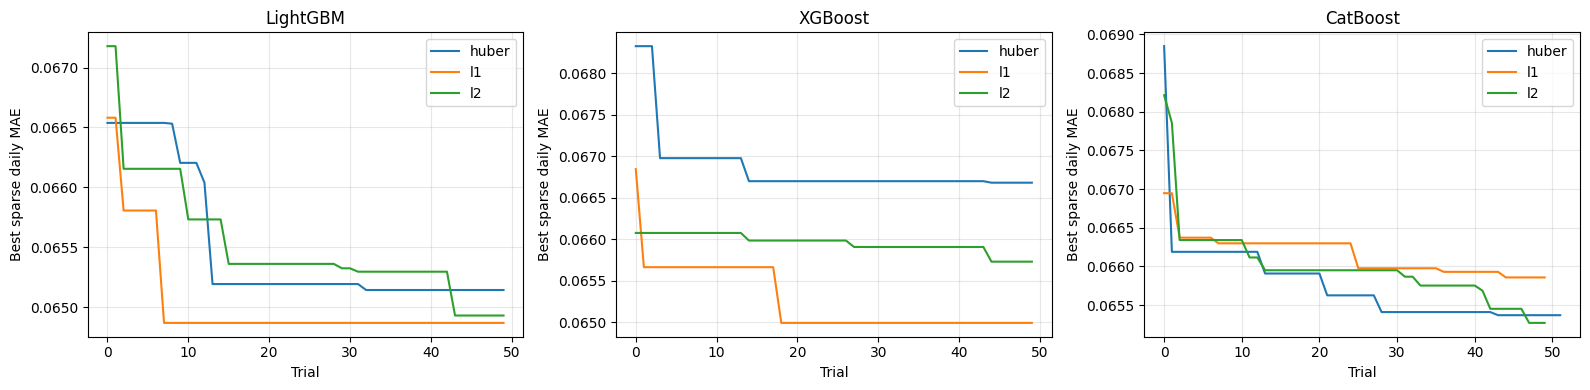

In [11]:
studies = {}


if RUN_SEARCH:
    for model_name, loss_names in LOSSES.items():
        for loss_name in loss_names:
            studies[(model_name, loss_name)] = run_search(
                model_name,
                loss_name,
                TRIALS_PER_LOSS[model_name],
            )

else:
    existing_study_names = set()
    storage_path = RESULTS_ROOT / "optuna_studies.sqlite3"

    if storage_path.exists():
        existing_study_names = {
            summary.study_name
            for summary in optuna.study.get_all_study_summaries(
                storage=STORAGE_URL
            )
        }

    for model_name, loss_names in LOSSES.items():
        for loss_name in loss_names:
            manifest = study_manifest(model_name, loss_name)
            study_name = (
                f"{model_name}_{loss_name}_"
                f"{object_hash(manifest)[:20]}"
            )

            if study_name in existing_study_names:
                studies[(model_name, loss_name)] = optuna.load_study(
                    study_name=study_name,
                    storage=STORAGE_URL,
                )


trial_rows = []

for (model_name, loss_name), study in studies.items():
    for trial in study.trials:
        if trial.state != optuna.trial.TrialState.COMPLETE:
            continue

        trial_rows.append(
            {
                "model": model_name,
                "loss": loss_name,
                "trial": trial.number,
                "mae_mean": trial.value,
                "weighting": trial.user_attrs["config"]["weighting"],
                "config": trial.user_attrs["config"],
            }
        )


trials_table = pd.DataFrame(trial_rows)

if trials_table.empty:
    print("Search has not been run. No best parameters are available yet.")

else:
    display(
        trials_table
        .drop(columns="config")
        .sort_values("mae_mean")
        .head(20)
    )

    display(
        trials_table
        .groupby(["model", "loss", "weighting"])
        .size()
        .rename("completed_trials")
    )

    write_json_atomic(
        OUTPUT_DIR / "completed_trials.json",
        trial_rows,
    )

    figure, axes = plt.subplots(
        1,
        len(LOSSES),
        figsize=(16, 4),
        squeeze=False,
    )

    for axis, model_name in zip(axes[0], LOSSES):
        model_trials = trials_table[
            trials_table["model"].eq(model_name)
        ]

        for loss_name, loss_trials in model_trials.groupby("loss"):
            loss_trials = loss_trials.sort_values("trial")
            axis.plot(
                loss_trials["trial"],
                loss_trials["mae_mean"].cummin(),
                label=loss_name,
            )

        axis.set_title(model_name)
        axis.set_xlabel("Trial")
        axis.set_ylabel("Best sparse daily MAE")
        axis.grid(alpha=0.3)

        if axis.lines:
            axis.legend()

    plt.tight_layout()
    plt.show()

### Full Development Evaluation and Finalist Selection

First, evaluate the best two configurations from each loss and the fixed L2
baseline from each model family on every development block, using the search
seed. This is at most 21 candidates. Keeping two per loss matters: in the first
run, sparse and full development rankings sometimes disagreed.

Then evaluate the best two candidates per family, plus its L2 baseline, with
the remaining selection seeds. This adds at most 9 candidates for the default
second seed. Only candidates checked with all selection seeds enter the final
ranking. Single-seed scores are saved separately and never mixed into it.

At 425 daily refits, this needs at most 12,750 fits instead of 22,950, before
cache reuse: about 44% fewer. It is a screening compromise; a candidate outside
the shortlist could still improve under another seed. Increase
`FINALISTS_PER_MODEL` if the preliminary leaders are tightly grouped or unstable.

The complete development period follows the configured history/refit policy.
The primary selection metric stays daily MAE. RMSE, R², bias, the 95th percentile
of absolute error, high-CF errors, and raw forecasts are diagnostics, not extra
objectives selected after seeing the holdout.


In [12]:
frozen_selection = None


if RUN_FINALISTS:
    expected_study_count = sum(len(loss_names) for loss_names in LOSSES.values())

    if len(studies) != expected_study_count:
        raise ValueError("Complete every requested loss study first.")

    candidate_configs = {}

    for (model_name, loss_name), study in studies.items():
        complete_trials = [
            trial
            for trial in study.trials
            if trial.state == optuna.trial.TrialState.COMPLETE
        ]

        if len(complete_trials) < TRIALS_PER_LOSS[model_name]:
            raise ValueError(f"Incomplete study: {model_name}/{loss_name}")

        best_trials = sorted(
            complete_trials,
            key=lambda trial: trial.value,
        )[:TOP_K_PER_LOSS]

        configs = [
            trial.user_attrs["config"]
            for trial in best_trials
        ]
        if loss_name == "l2":
            configs.append(baseline_config(model_name, "l2"))

        for config in configs:
            candidate_configs[object_hash(config)] = config

    selection_id = object_hash(
        {
            "experiment_id": EXPERIMENT_ID,
            "candidates": candidate_configs,
            "seeds": FINAL_SEEDS,
            "screening": "full development, first seed, then family shortlist",
            "finalists_per_model": FINALISTS_PER_MODEL,
        }
    )[:20]
    selection_dir = OUTPUT_DIR / f"selection_{selection_id}"
    selection_dir.mkdir(parents=True, exist_ok=True)

    preliminary_rows = []

    for candidate_id, config in tqdm(candidate_configs.items(), desc="Development screening", unit="candidate"):
        predictions, fit_audit = evaluate_config(
            config, development_blocks, seeds=[FINAL_SEEDS[0]], show_progress=True,
        )
        predictions.to_parquet(selection_dir / f"{candidate_id}_screen.parquet", index=False)
        preliminary_rows.append({
            "candidate": candidate_id,
            "model": config["model"],
            "loss": config["loss"],
            **summarize_predictions(predictions),
        })

    preliminary_ranking = pd.DataFrame(preliminary_rows).sort_values(["mae_mean", "candidate"])
    preliminary_ranking.to_csv(selection_dir / "preliminary_ranking.csv", index=False)
    display(preliminary_ranking)

    # Keep the fixed baselines as controls, even if they miss the shortlist.
    promoted_ids = set(
        preliminary_ranking.groupby("model", sort=False).head(FINALISTS_PER_MODEL)["candidate"]
    )
    promoted_ids.update(object_hash(baseline_config(name)) for name in LOSSES)
    ranking_rows = []

    for candidate_id in tqdm(sorted(promoted_ids), desc="Development seed check", unit="candidate"):
        config = candidate_configs[candidate_id]
        predictions, fit_audit = evaluate_config(
            config, development_blocks, seeds=FINAL_SEEDS, show_progress=True,
        )
        predictions.to_parquet(selection_dir / f"{candidate_id}.parquet", index=False)
        ranking_rows.append({
            "candidate": candidate_id,
            "model": config["model"],
            "loss": config["loss"],
            **summarize_predictions(predictions),
            "train_mae": float(fit_audit["train_mae"].mean()),
            "validation_minus_train_mae": float(
                fit_audit["validation_mae"].mean() - fit_audit["train_mae"].mean()
            ),
            "mean_fit_seconds": float(fit_audit["fit_seconds"].mean()),
        })

    finalist_ranking = pd.DataFrame(ranking_rows).sort_values(
        ["mae_mean", "candidate"]
    ).reset_index(drop=True)

    # Compare losses on the same first seed, including losses screened out later.
    loss_comparison = preliminary_ranking.groupby(["model", "loss"], sort=False).head(1)
    loss_comparison.to_csv(selection_dir / "development_loss_comparison.csv", index=False)
    display(loss_comparison[[
        "model", "loss", "mae_mean", "rmse_pooled", "r2_pooled", "bias",
        "p95_absolute_error", "high_cf_mae", "raw_prediction_min", "raw_prediction_max",
    ]])

    best_by_model = (
        finalist_ranking
        .groupby("model", sort=False)
        .head(1)
    )
    development_winner = finalist_ranking.iloc[0]

    finalist_ranking.to_csv(
        selection_dir / "finalist_ranking.csv",
        index=False,
    )

    frozen_selection = {
        "experiment_id": EXPERIMENT_ID,
        "selection_id": selection_id,
        "frozen_at_utc": str(pd.Timestamp.now(tz="UTC")),
        "metric": "mean daily clipped capacity-factor MAE",
        "fit_protocol": FIT_PROTOCOL,
        "dataset_hash": DATASET_HASH,
        "deployment_seed": SEED,
        "selection_seeds": FINAL_SEEDS,
        "development_end": str(development_days.max().date()),
        "development_winner": candidate_configs[
            development_winner["candidate"]
        ],
        "best_by_model": {
            row.model: candidate_configs[row.candidate]
            for row in best_by_model.itertuples()
        },
        "development_scores": finalist_ranking.to_dict(orient="records"),
    }

    frozen_path = selection_dir / "frozen_selection.json"

    if frozen_path.exists():
        saved_selection = json.loads(
            frozen_path.read_text(encoding="utf-8")
        )

        if saved_selection["selection_id"] != selection_id:
            raise ValueError("Existing frozen selection has a different identity.")

        frozen_selection = saved_selection

    else:
        write_json_atomic(frozen_path, frozen_selection)

    write_json_atomic(
        OUTPUT_DIR / "latest_selection.json",
        {
            "selection_id": selection_id,
            "path": str(frozen_path),
        },
    )

    display(finalist_ranking)
    print("Frozen selection:", frozen_path)

else:
    latest_selection_path = OUTPUT_DIR / "latest_selection.json"

    if latest_selection_path.exists():
        selection_pointer = json.loads(
            latest_selection_path.read_text(encoding="utf-8")
        )
        frozen_selection = json.loads(
            Path(selection_pointer["path"]).read_text(encoding="utf-8")
        )

        if frozen_selection["experiment_id"] != EXPERIMENT_ID:
            raise ValueError("Frozen selection belongs to another experiment.")

    print(
        "Frozen selection available:",
        frozen_selection is not None,
    )


Development screening: 100%|██████████| 21/21 [00:35<00:00,  1.69s/candidate]


,candidate,model,loss,mae_mean,mae_std,seed_mae_std,seed_mae_min,seed_mae_max,rmse_pooled,r2_pooled,bias,p95_absolute_error,high_cf_mae,high_cf_rows,high_cf_days,target_rows,target_days,n_seeds,raw_outside_fraction,raw_prediction_min,raw_prediction_max
3,4e4f9328f5559bbba38ad5f3dce13664d099916d68d742...,LightGBM,l1,0.06443,0.03544,None,0.06443,0.06443,0.08828,0.85571,-0.00544,0.18749,0.09004,7273,196,40796,425,1,0.00186,-0.00834,0.78800
19,9b007a61b7c24ec9809aa3acce66cd3d390acbcea09b98...,CatBoost,huber,0.06470,0.03596,None,0.06470,0.06470,0.08868,0.85442,-0.00010,0.18839,0.08744,7273,196,40796,425,1,0.00282,-0.03580,0.77420
15,259e964500a16140533ab5add6c3f1c84fe2b926d84174...,CatBoost,l2,0.06473,0.03632,None,0.06473,0.06473,0.08869,0.85436,-0.00112,0.18810,0.08733,7273,196,40796,425,1,0.00049,-0.02292,0.78381
14,1f8bef3874ed541eb8f5f6d7881660fb44fc919f4e703d...,CatBoost,l2,0.06486,0.03604,None,0.06486,0.06486,0.08876,0.85415,-0.00218,0.18901,0.08845,7273,196,40796,425,1,0.00002,-0.00095,0.77505
17,1f3eba17836dbb7873115c1a3f0a84afe58fb5772cc56a...,CatBoost,l1,0.06491,0.03717,None,0.06491,0.06491,0.08987,0.85047,-0.00405,0.19239,0.08762,7273,196,40796,425,1,0.00385,-0.02458,0.77856
20,38faed8216d08da2e98a455cd406eb49dd1a77ea674f4a...,CatBoost,huber,0.06498,0.03648,None,0.06498,0.06498,0.08904,0.85323,-0.00700,0.18864,0.09247,7273,196,40796,425,1,0.00194,-0.02730,0.78758
18,dcc5628c66aba408674f3df7bb0dafb36f09b06afd8c29...,CatBoost,l1,0.06506,0.03718,None,0.06506,0.06506,0.08989,0.85039,-0.00453,0.19136,0.08750,7273,196,40796,425,1,0.00299,-0.05070,0.78918
5,8c2c36b92da13a7466b0e9eac09e66469db89ca644f262...,LightGBM,huber,0.06509,0.03660,None,0.06509,0.06509,0.08934,0.85224,-0.00121,0.18941,0.08669,7273,196,40796,425,1,0.00007,-0.00121,0.77012
6,fa02e4aca8833231011e45dddb0349dbaf5ab1b621b81a...,LightGBM,huber,0.06522,0.03606,None,0.06522,0.06522,0.08906,0.85314,-0.00300,0.18766,0.08880,7273,196,40796,425,1,0.00005,-0.00294,0.76554
0,e4633d437a2f0b1f4cdb5313eb8467e687a421bfa0eeac...,LightGBM,l2,0.06528,0.03663,None,0.06528,0.06528,0.08943,0.85193,0.00001,0.19071,0.08469,7273,196,40796,425,1,0.00002,-0.00113,0.77500


Development seed check: 100%|██████████| 9/9 [00:29<00:00,  3.27s/candidate]


,model,loss,mae_mean,rmse_pooled,r2_pooled,bias,p95_absolute_error,high_cf_mae,raw_prediction_min,raw_prediction_max
3,LightGBM,l1,0.06443,0.08828,0.85571,-0.00544,0.18749,0.09004,-0.00834,0.78800
19,CatBoost,huber,0.06470,0.08868,0.85442,-0.00010,0.18839,0.08744,-0.03580,0.77420
15,CatBoost,l2,0.06473,0.08869,0.85436,-0.00112,0.18810,0.08733,-0.02292,0.78381
17,CatBoost,l1,0.06491,0.08987,0.85047,-0.00405,0.19239,0.08762,-0.02458,0.77856
5,LightGBM,huber,0.06509,0.08934,0.85224,-0.00121,0.18941,0.08669,-0.00121,0.77012
0,LightGBM,l2,0.06528,0.08943,0.85193,0.00001,0.19071,0.08469,-0.00113,0.77500
10,XGBoost,l1,0.06564,0.08999,0.85005,-0.00675,0.19083,0.09216,-0.01454,0.79139
12,XGBoost,huber,0.06575,0.08978,0.85077,-0.00590,0.19161,0.09185,-0.02613,0.78790
7,XGBoost,l2,0.06606,0.09084,0.84721,-0.00376,0.19264,0.08944,-0.02324,0.79313


,candidate,model,loss,mae_mean,mae_std,seed_mae_std,seed_mae_min,seed_mae_max,rmse_pooled,r2_pooled,bias,p95_absolute_error,high_cf_mae,high_cf_rows,high_cf_days,target_rows,target_days,n_seeds,raw_outside_fraction,raw_prediction_min,raw_prediction_max,train_mae,validation_minus_train_mae,mean_fit_seconds
0,4e4f9328f5559bbba38ad5f3dce13664d099916d68d742...,LightGBM,l1,0.06459,0.03551,0.00023,0.06443,0.06476,0.08851,0.85497,-0.00550,0.18876,0.09002,7273,196,40796,425,2,0.00180,-0.00834,0.78800,0.04699,0.01760,0.37945
1,9b007a61b7c24ec9809aa3acce66cd3d390acbcea09b98...,CatBoost,huber,0.06471,0.03594,0.00002,0.06470,0.06473,0.08865,0.85449,-0.00008,0.18761,0.08747,7273,196,40796,425,2,0.00322,-0.03580,0.77768,0.04200,0.02272,10.84834
2,259e964500a16140533ab5add6c3f1c84fe2b926d84174...,CatBoost,l2,0.06474,0.03621,0.00002,0.06473,0.06476,0.08870,0.85434,-0.00121,0.18778,0.08726,7273,196,40796,425,2,0.00051,-0.03606,0.78425,0.04499,0.01975,3.24324
3,8c2c36b92da13a7466b0e9eac09e66469db89ca644f262...,LightGBM,huber,0.06515,0.03661,0.00007,0.06509,0.06520,0.08944,0.85190,-0.00119,0.18997,0.08646,7273,196,40796,425,2,0.00005,-0.00121,0.77346,0.04389,0.02126,0.70357
4,8738402e5efee370b908f5b993273ddb2fa514852931d2...,XGBoost,l1,0.06559,0.03756,0.00007,0.06554,0.06564,0.09017,0.84947,-0.00686,0.19245,0.09238,7273,196,40796,425,2,0.00157,-0.01786,0.80680,0.03340,0.03219,3.15408
5,9129f9723890f91075717887c299e804eeefdf27e23b24...,XGBoost,l1,0.06571,0.03710,0.00009,0.06564,0.06577,0.09010,0.84970,-0.00674,0.19115,0.09260,7273,196,40796,425,2,0.00173,-0.02202,0.80293,0.03334,0.03237,3.51911
6,98ceeed1c5aeab6005b0cc490b9e0a7ed8263e3d91121c...,XGBoost,l2,0.06677,0.03786,0.00004,0.06675,0.06680,0.09134,0.84554,-0.00678,0.19451,0.09539,7273,196,40796,425,2,0.00069,-0.01717,0.77689,0.04667,0.02010,0.34338
7,21d600613318312898580b7eac6367ec84322f1f745ee4...,LightGBM,l2,0.06693,0.03780,0.00030,0.06672,0.06714,0.09144,0.84519,-0.00654,0.19291,0.09496,7273,196,40796,425,2,0.00051,-0.01223,0.77671,0.04696,0.01996,0.27405
8,ebf417f77d9cb238c578d58c5894fff1fbf5105ee9a331...,CatBoost,l2,0.06752,0.03755,0.00013,0.06743,0.06762,0.09180,0.84397,-0.00703,0.19519,0.09992,7273,196,40796,425,2,0.00001,-0.00043,0.76852,0.05552,0.01201,0.63520


Frozen selection: D:\python_projects\entsoe_1st_try\results\offshore_joint_loss_hpo\c550de332f450772dce8\selection_d2085702a714cb374154\frozen_selection.json


### Final Holdout Comparison

The holdout is evaluated **only after** the best configuration from each model family has been frozen on development data.

The table compares the three family winners on the same target days. The interactive chart shows actual capacity factor and all three forecasts, with a range slider for closer inspection.

The development winner remains **recorded separately**. If another family looks better on this holdout, that is a final model-family comparison result, the hyperparameters are **not tuned again** on these dates.

Fixed L2 baselines are evaluated on the same holdout days as the family winners.
The plot includes development forecasts for the frozen configurations and marks
the holdout boundary. Development forecasts helped select these configurations,
their plotted quality is therefore not an independent performance estimate.

In [13]:
holdout_predictions = {}
holdout_summary_rows = []


if RUN_HOLDOUT:
    if frozen_selection is None:
        raise ValueError("Run and freeze the full finalist evaluation first.")

    selection_dir = (
        OUTPUT_DIR
        / f"selection_{frozen_selection['selection_id']}"
    )
    holdout_dir = selection_dir / "holdout"
    holdout_dir.mkdir(parents=True, exist_ok=True)

    for model_name, config in frozen_selection["best_by_model"].items():
        predictions, fit_audit = evaluate_config(
            config,
            holdout_blocks,
            seeds=[frozen_selection["deployment_seed"]],
            show_progress=True,
        )

        holdout_predictions[model_name] = predictions
        metrics = summarize_predictions(predictions)

        predictions.to_parquet(
            holdout_dir / f"{model_name}_predictions.parquet",
            index=False,
        )
        holdout_summary_rows.append(
            {
                "model": model_name,
                "loss": config["loss"],
                **metrics,
                "mean_fit_seconds": float(
                    fit_audit["fit_seconds"].mean()
                ),
            }
        )

    holdout_summary = (
        pd.DataFrame(holdout_summary_rows)
        .sort_values("mae_mean")
        .reset_index(drop=True)
    )
    holdout_summary.to_csv(
        holdout_dir / "model_family_comparison.csv",
        index=False,
    )

    display(holdout_summary)

    # Reuse saved development predictions for the exact deployment seed.
    history_predictions = {}
    for model_name, config in frozen_selection["best_by_model"].items():
        development_prediction = pd.read_parquet(
            selection_dir / f"{object_hash(config)}.parquet"
        )
        development_prediction = development_prediction.loc[
            development_prediction["seed"].eq(frozen_selection["deployment_seed"])
        ]
        combined = pd.concat(
            [development_prediction, holdout_predictions[model_name]], ignore_index=True,
        ).sort_values("row")
        if combined["row"].duplicated().any():
            raise ValueError("Development and holdout predictions overlap.")
        history_predictions[model_name] = combined
        combined.to_parquet(holdout_dir / f"{model_name}_full_history.parquet", index=False)

    baseline_rows = []
    for model_name in tqdm(LOSSES, desc="Holdout baselines", unit="model"):
        baseline_prediction, _ = evaluate_config(
            baseline_config(model_name), holdout_blocks,
            seeds=[frozen_selection["deployment_seed"]], show_progress=True,
        )
        baseline_prediction.to_parquet(holdout_dir / f"{model_name}_baseline.parquet", index=False)
        baseline_rows.append({"model": model_name, **summarize_predictions(baseline_prediction)})
    baseline_summary = pd.DataFrame(baseline_rows)
    baseline_summary.to_csv(holdout_dir / "baseline_comparison.csv", index=False)
    comparison = holdout_summary.merge(
        baseline_summary[["model", "mae_mean", "rmse_pooled"]],
        on="model", suffixes=("", "_baseline"),
    )
    comparison["mae_gain_percent"] = 100 * (1 - comparison["mae_mean"] / comparison["mae_mean_baseline"])
    display(comparison)

    first_model_name = next(iter(history_predictions))
    actual = (
        history_predictions[first_model_name]
        .sort_values("target_time")
    )

    figure = go.Figure()
    figure.add_scatter(
        x=actual["target_time"],
        y=actual["actual"],
        name="Actual CF",
        mode="lines",
        line={"width": 2, "color": "black"},
    )

    colors = {
        "LightGBM": "#2ca02c",
        "XGBoost": "#1f77b4",
        "CatBoost": "#ff7f0e",
    }

    for model_name, predictions in history_predictions.items():
        predictions = predictions.sort_values("target_time")
        config = frozen_selection["best_by_model"][model_name]

        figure.add_scatter(
            x=predictions["target_time"],
            y=predictions["prediction"],
            name=f"{model_name} ({config['loss']})",
            mode="lines",
            line={
                "width": 1.2,
                "color": colors[model_name],
            },
            opacity=0.85,
        )

    boundary = holdout_start.tz_localize(TIMEZONE).isoformat()
    figure.add_shape(
        type="line", x0=boundary, x1=boundary, y0=0, y1=1,
        xref="x", yref="paper", line={"color": "red", "dash": "dash", "width": 2},
    )
    figure.add_annotation(
        x=boundary, y=1, xref="x", yref="paper", text="Holdout starts",
        showarrow=False, xanchor="right", yanchor="bottom",
    )

    figure.update_layout(
        title=(
            "Development and holdout forecasts from the best configuration "
            f"in each model family | {TRAIN_WINDOW_DAYS}/"
            f"{RETRAIN_INTERVAL_DAYS}"
        ),
        template="plotly_white",
        xaxis={
            "title": "Target time (Europe/Berlin)",
            "rangeslider": {"visible": True},
        },
        yaxis={
            "title": "Capacity factor",
            "range": [-0.02, 1.02],
        },
        hovermode="x unified",
        height=560,
    )

    figure.write_html(
        holdout_dir / "model_family_predictions.html",
        include_plotlyjs=True,
    )
    figure.show()

else:
    print("Holdout comparison has not been run.")


,model,loss,mae_mean,mae_std,seed_mae_std,seed_mae_min,seed_mae_max,rmse_pooled,r2_pooled,bias,p95_absolute_error,high_cf_mae,high_cf_rows,high_cf_days,target_rows,target_days,n_seeds,raw_outside_fraction,raw_prediction_min,raw_prediction_max,mean_fit_seconds
0,CatBoost,huber,0.04788,0.03063,None,0.04788,0.04788,0.06999,0.82718,0.00608,0.14248,0.07271,34,2,2688,28,1,0.01190,-0.01362,0.59485,11.07077
1,XGBoost,l1,0.04946,0.03008,None,0.04946,0.04946,0.07091,0.82262,-0.00015,0.15539,0.07746,34,2,2688,28,1,0.00074,-0.00048,0.60086,3.11098
2,LightGBM,l1,0.05225,0.03199,None,0.05225,0.05225,0.07473,0.80300,0.00033,0.15794,0.08586,34,2,2688,28,1,0.00521,-0.00243,0.58175,0.33217


Holdout baselines: 100%|██████████| 3/3 [00:33<00:00, 11.32s/model]


,model,loss,mae_mean,mae_std,seed_mae_std,seed_mae_min,seed_mae_max,rmse_pooled,r2_pooled,bias,p95_absolute_error,high_cf_mae,high_cf_rows,high_cf_days,target_rows,target_days,n_seeds,raw_outside_fraction,raw_prediction_min,raw_prediction_max,mean_fit_seconds,mae_mean_baseline,rmse_pooled_baseline,mae_gain_percent
0,CatBoost,huber,0.04788,0.03063,None,0.04788,0.04788,0.06999,0.82718,0.00608,0.14248,0.07271,34,2,2688,28,1,0.01190,-0.01362,0.59485,11.07077,0.04980,0.07190,3.85002
1,XGBoost,l1,0.04946,0.03008,None,0.04946,0.04946,0.07091,0.82262,-0.00015,0.15539,0.07746,34,2,2688,28,1,0.00074,-0.00048,0.60086,3.11098,0.04966,0.07144,0.40133
2,LightGBM,l1,0.05225,0.03199,None,0.05225,0.05225,0.07473,0.80300,0.00033,0.15794,0.08586,34,2,2688,28,1,0.00521,-0.00243,0.58175,0.33217,0.05026,0.07233,-3.95476


### What This Notebook Establishes

This notebook creates a reproducible comparison of training losses, capacity-factor weights, and model hyperparameters under the selected production history regime.

The most important design choices are:

- the loss and model parameters are tuned together;
- the refit schedule used during HPO is the same schedule used during full validation;
- the target-day labels never affect model fitting;
- overfit gaps are diagnostics rather than arbitrary rejection rules;
- the holdout comes from the project-wide `.env` setting;
- cached fits are tied to the full statistical configuration and source code.

The final answer is produced only after the long search and finalist stages have run. The default notebook execution verifies the implementation but does not claim to have found the best production parameters.